# Choosing the prediction models: Super Learner ensembles in TMLE

## At a glance

Every TMLE (targeted maximum likelihood estimation) fit trains two prediction models: one for the outcome and one for who got the
treatment. This page shows how to choose them, using the navigation program of [one treatment, one
outcome](point-treatment-tmle.ipynb): would offering navigation to every eligible patient going home
from hospital raise their 30-day transition score, a patient-reported score from 0 to 1?

Instead of betting on one model, the page lets cross-validation blend three candidates for each
model, from a straight line to shallow gradient boosting (a blend called a Super Learner). With
those blends, offering navigation to everyone would raise the average score by 0.174, with a 95%
confidence interval of 0.155 to 0.192; the simulated data's true effect is 0.163.

The caveat: a blend can only be as good as its candidates, and the answer is causal only if no
unrecorded factor drove both the offer and the score (a hidden confounder).

## The question

The program gives a patient a bedside plan and two navigator calls in the 30 days after discharge.
The quantity to estimate is the average treatment effect (ATE): how much the average score would
change if every eligible patient got the offer, compared with no one. TMLE fits an outcome model,
which predicts the score from the offer and four patient characteristics, and a treatment model,
which predicts each patient's chance of the offer. A correction step then nudges the outcome
model's predictions, with weights from the treatment model that are larger for patients whose actual
option, offer or no offer, was unlikely, so that the outcome model's bias does not carry into the estimate. The question here is
which two models to use.

## The data

Every fit sets its seeds, so a rerun with the version printed below gives the same numbers. This
page needs pandas, scikit-learn and matplotlib: `pip install "cleverly[all]"`.

In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer

import cleverly

pd.set_option("display.width", 130)
print("cleverly", cleverly.__version__)

cleverly 0.2.8


`navigation_data` draws 1,000 simulated discharges and their true effect, which real data never
give.

In [2]:
from cleverly.datasets import navigation_data

# With your own data, load your data frame here, such as frame = pd.read_csv(...).
# Real data have no `truth`, so drop every line that uses it.
frame, truth = navigation_data(n=1_000, seed=52)
# The characteristics to adjust for: measured before the offer, and causes of both the
# offer and the score.
covariates = ["discharge_risk", "prior_utilization", "medication_burden", "age"]
print("rows and columns:", frame.shape)
print(list(frame.columns))
print(frame.head().round(3))

rows and columns: (1000, 6)
['transition_score', 'transition_navigation', 'discharge_risk', 'prior_utilization', 'medication_burden', 'age']
   transition_score  transition_navigation  discharge_risk  prior_utilization  medication_burden    age
0             0.144                    1.0          -0.826              0.243             -0.064 -0.094
1             0.461                    1.0           0.323              0.666              0.189  0.178
2             0.286                    0.0          -1.137              0.578             -0.326  0.990
3             0.795                    0.0           1.313             -1.633              1.330 -0.681
4             0.163                    1.0          -1.038             -0.232              0.299  1.009


Each row is one discharge: the score, the offer (1 or 0), and four characteristics measured before
the offer, on a standardized scale. In the simulation, all four change both the chance of an offer
and the score, and they do so along curves and through interactions, which no straight-line model
can follow.

## Why a simple comparison misleads

Staff chose who got the offer, so offered and other patients differ before the offer.

In [3]:
by_arm = frame.groupby("transition_navigation")["transition_score"].mean()
print(f"unadjusted difference in mean score: {by_arm[1.0] - by_arm[0.0]:.3f}")
print(f"population ATE:                      {truth['ate']:.3f}")
print(f"mean score, patients not offered:     {by_arm[0.0]:.3f}")

unadjusted difference in mean score: 0.192
population ATE:                      0.163
mean score, patients not offered:     0.398


Offered patients score 0.192 higher, more than the true 0.163, because staff offered navigation more
often to patients who score higher anyway.

## Set up the analysis

The study description (`StudyProtocol`) and the conditions are those of the [one treatment, one
outcome](point-treatment-tmle.ipynb) example, which explains each field. Then name the outcome, the
treatment and the characteristics to adjust for (`PointTreatment`), and the quantity to estimate
(`ATE(reference=0)`). `identify` checks that the data can answer that question and lists the
conditions the answer rests on.

In [4]:
from cleverly.datasets import navigation_protocol

# This page's program comes with its study description already filled in. For your own
# study, build a StudyProtocol as the point-treatment example shows.
protocol = navigation_protocol()
print("\n".join(protocol.summary_lines()))

Population: Adults with a discharge-home order at a participating hospital during the enrollment period
Eligibility: Age 18 years or older; Discharge home ordered at a participating hospital
Follow-up starts: Discharge-home order, after baseline measurement and before the navigation offer
Strategies: Offer standard transition navigation; Provide usual discharge support
Versions: Bedside transition plan and two scheduled navigator contacts within 30 days; No access to the transition-navigation offer
Outcome: Patient-reported transition score, as a share of the maximum score
Horizon: 30 days after discharge
Intercurrent events: Use the transition score regardless of readmission; Analyze the offer regardless of completed contacts; The protocol scores death before day 30 as the worst transition score (composite strategy)
Interference unit: Individual patient
Rationale: The recorded baseline variables cover the measured common causes; Standardized offer and version records support that each

In [5]:
from cleverly import ATE, CausalStudy, PointTreatment

# For your own data, change the outcome and treatment names and the `covariates` list.
study = CausalStudy(
    frame,
    design=PointTreatment(
        outcome="transition_score",
        treatment="transition_navigation",
        adjustment=tuple(covariates),
    ),
    protocol=protocol,
)
effect = study.identify(ATE(reference=0))
print(effect.summary())

                            Causal question (ate)
Question:      average effect of        Rows:                            1,000
               transition_navigation    Answered by:  adjusting for covariates
               on transition_score (1
               compared with 0)
Outcome:       transition_score
               (continuous)
Treatment:     transition_navigation
               (levels 0, 1)
Adjusted for:  discharge_risk,
               prior_utilization,
               medication_burden, age
Conditions the answer rests on
condition                checkable   what it says
------------------------------------------------------------------------------
well-defined treatment   no          Each unit's observed outcome is the
                                     outcome it would have had under the
                                     treatment it actually received. This
                                     needs the treatment to be well defined:
                                    

The answer is causal under the four conditions listed: one meaning of an offer, no effect of one
patient's offer on another's score, no unrecorded common cause of the offer and the score, and
overlap, meaning every kind of patient had a real chance of either option. Only overlap can be
partly checked in the data, which "Check the fit" does below.

## Count the work before you fit

Leave the models out of the method (`ModelSpec`) and `cleverly` uses its default for each one: a
Super Learner over three candidates, histogram gradient boosting, a random forest and a lasso. A
Super Learner scores each candidate by cross-validation inside the training rows, then blends their
predictions with weights that are zero or more and add up to one, chosen to give the smallest
cross-validated error. `planned_fits` counts the models a fit would train without training any.

In [6]:
from cleverly import CrossFitting, Runtime, Targeting, TMLEMethod
from cleverly.learners import default_library

print("default candidates:", [name for name, _ in default_library("classification")])
# The method of the default fit: no ModelSpec, so both models use the default ensemble.
# Five outer folds instead of the default ten keep this page's run short.
default_method = TMLEMethod(
    cross_fitting=CrossFitting(n_folds=5),
    # The range the outcome can take: set your own outcome's range here, or drop this line
    # for a yes-or-no outcome.
    targeting=Targeting(q_bounds=(0.0, 1.0)),
    runtime=Runtime(random_state=52, n_jobs=1),
)
planned = effect.planned_fits(method=default_method)
print("model fits:    ", planned.total_fits)
print("candidate fits:", planned.total_candidate_fits)
print(planned.summary())

default candidates: ['hist_gradient_boosting', 'random_forest', 'lasso']
model fits:     10
candidate fits: 180
                              Planned model fits
Model fits:      10                     Count:                           exact
Candidate fits:  180                    Folds:  the ones the fit uses (seeded)
Fits by model
model                   fits   candidate fits   what and how often
------------------------------------------------------------------------------
treatment_learner          5               90   treatment mechanism, per fold
                                                and repeat
outcome_learner            5               90   outcome regression, per fold
                                                and repeat
Learners
model               learner
------------------------------------------------------------------------------
treatment_learner   super learner (default library)
outcome_learner     super learner (default library)
Fits by candidate
candidate 

With five outer folds (five groups of patients, each predicted by models trained on the other
four), each of the two models is fitted once per fold, and each fit trains its 3 candidates on 5
inner folds plus once on all its rows: 180 candidate fits, with a 5-fold search inside every lasso
([count the model
fits](../user-guide/methods-learners.md#count-the-model-fits-before-a-long-run) explains these
counts). Checks that refit the analysis many times multiply that cost.

## An ensemble you choose

Each model gets three candidates, ordered from simple to flexible:

- a straight line (linear or logistic regression), which is right only if every effect is a
  straight line;
- additive splines, which bend each characteristic's effect into a smooth curve but add the curves
  without interactions;
- gradient boosting with two-level trees and a penalty (`shallow_booster`), which can follow
  interactions. Shallow trees and the penalty keep it from memorizing rows, as on the [flexible
  models](cross-fitting.ipynb) page.

`SuperLearner(n_folds=3)` scores the candidates on three inner folds instead of the default five,
which cuts the candidate fits from 180 to 120, and `clip=(0.0, 1.0)` keeps the predicted score
inside its known range.

In [7]:
from cleverly import ModelSpec, SuperLearner


def shallow_booster(kind):
    """Gradient boosting with two-level trees and a penalty, so it cannot memorize rows."""
    return kind(max_depth=2, learning_rate=0.05, max_iter=200, l2_regularization=1.0)


# For your own data, list the candidates you would consider, from simple to flexible.
outcome_ensemble = SuperLearner(
    library=[
        ("linear", LinearRegression()),
        ("splines", make_pipeline(SplineTransformer(n_knots=5), RidgeCV())),
        ("boosting", shallow_booster(HistGradientBoostingRegressor)),
    ],
    n_folds=3,
    clip=(0.0, 1.0),  # the outcome's known range, as in q_bounds below
    random_state=52,
)
treatment_ensemble = SuperLearner(
    library=[
        ("logistic", LogisticRegression(max_iter=1000)),
        ("splines", make_pipeline(SplineTransformer(n_knots=5), LogisticRegression(max_iter=2000))),
        ("boosting", shallow_booster(HistGradientBoostingClassifier)),
    ],
    n_folds=3,
    random_state=52,
)
declared_method = TMLEMethod(
    models=ModelSpec(outcome_learner=outcome_ensemble, treatment_learner=treatment_ensemble),
    cross_fitting=CrossFitting(n_folds=5),
    targeting=Targeting(q_bounds=(0.0, 1.0)),
    runtime=Runtime(random_state=52, n_jobs=1),
)
declared = effect.estimate(method=declared_method)
estimate = declared["ate"]
print(
    f"declared ensembles: ATE {estimate.psi:.4f}, standard error {estimate.std_error:.4f}, "
    f"95% interval {estimate.ci[0]:.4f} to {estimate.ci[1]:.4f}"
)
print(f"population ATE:     {truth['ate']:.4f}")
print("candidate fits:", effect.planned_fits(method=declared_method).total_candidate_fits)

declared ensembles: ATE 0.1736, standard error 0.0094, 95% interval 0.1552 to 0.1920
population ATE:     0.1629
candidate fits: 120


The blended fit's 95% interval, 0.155 to 0.192, contains the true 0.163. In 200 simulated repeats
of this fit, its interval contained the truth 190 times, as a 95% interval should. The interval is
valid in large samples when both models are reasonably accurate and patients' results are
independent ([the conditions](../technical-reference/cv-tmle.md#what-this-solves)).

## What the weights and risks say

A candidate's cross-validated risk is its error on rows it did not train on: log loss for the
treatment model and mean squared error for the outcome model, so lower is better. Risks and weights
are averages over the five outer folds. `plotting.learners` draws them, with a risk panel and a
weight panel for each model.

          model candidate  cross-validated risk  weight
treatment model  logistic                0.6845  0.2409
treatment model   splines                0.6756  0.4112
treatment model  boosting                0.6855  0.3479
  outcome model    linear                0.0325  0.0000
  outcome model   splines                0.0215  0.2553
  outcome model  boosting                0.0198  0.7447


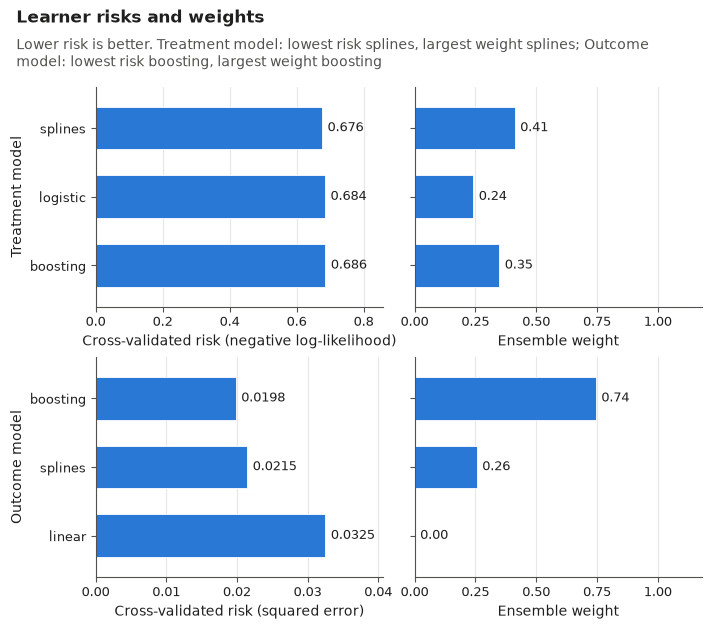

In [8]:
from cleverly import plotting


def weight_table(result):
    """Each model's candidates with their cross-validated risk and ensemble weight."""
    rows = []
    for model in result.diagnostics.nuisance_models().models:
        label = {"propensity": "treatment model", "outcome": "outcome model"}[model.name]
        for name, weight in model.learner_weights.items():
            rows.append(
                {
                    "model": label,
                    "candidate": name,
                    "cross-validated risk": model.learner_risks[name],
                    "weight": weight,
                }
            )
    return pd.DataFrame(rows)


weights = weight_table(declared)
print(weights.round(4).to_string(index=False))
learners_fig = plotting.learners(declared)

The outcome model leans on boosting (weight 0.74) with some splines (0.26), and gives the straight
line no weight: its risk, 0.0325, is far above boosting's 0.0198, because the score follows curves
and interactions. The treatment model spreads its weight over all three,
because their risks are nearly equal. A zero weight means the candidate added nothing
once the others were in the blend, not that it predicts badly on its own. Compare risks within a
model only, since the two models use different losses.

In large samples the outcome model's blend does about as well as the best mix of its candidates;
the same result for the treatment model's log loss is not verified here ([what that result
covers](../technical-reference/nuisance-learners.md#what-the-oracle-result-covers)). No blend beats
what its candidates can reach, so put at least one flexible candidate in each library.

## What the default ensemble does

To see the default library's choices cheaply, fit the default Super
Learner once on all 1,000 rows for each model, as each outer fold of the default fit would on its
training rows.

In [9]:
# The default ensemble, fitted once on every row for each model, as each outer fold of
# the default fit would: five inner folds, and predicted scores kept inside 0 to 1.
offer = frame["transition_navigation"].to_numpy()
score = frame["transition_score"].to_numpy()
default_treatment = SuperLearner(task="classification", n_folds=5, random_state=52)
default_treatment.fit(frame[covariates].to_numpy(), offer)
default_outcome = SuperLearner(task="regression", n_folds=5, clip=(0.0, 1.0), random_state=52)
default_outcome.fit(frame[["transition_navigation", *covariates]].to_numpy(), score)
rows = []
for label, ensemble in (("treatment model", default_treatment), ("outcome model", default_outcome)):
    found = ensemble.diagnostics_
    for name, risk, weight in zip(found.names, found.cv_risk, found.weights, strict=True):
        rows.append(
            {"model": label, "candidate": name, "cross-validated risk": risk, "weight": weight}
        )
print(pd.DataFrame(rows).round(4).to_string(index=False))

          model              candidate  cross-validated risk  weight
treatment model hist_gradient_boosting                0.7301  0.0930
treatment model          random_forest                0.6675  0.5833
treatment model                  lasso                0.6821  0.3236
  outcome model hist_gradient_boosting                0.0206  0.6315
  outcome model          random_forest                0.0213  0.2780
  outcome model                  lasso                0.0318  0.0905


The default outcome model also leans on boosting (0.63), with the forest second (0.28). Its
treatment model leans on the forest (0.58) and the lasso (0.32), and nearly drops boosting, whose
risk of 0.7301 is the worst of the treatment candidates. The default booster grows trees of up to
15 leaves for 200 rounds with no early stopping, and its high held-out risk is the sign of a model
that fits noise in who got the offer. Scoring candidates on held-out rows caught it and gave it a weight of
only 0.09. Use the default when you have no view of the candidates, and declare your own library when you
need fewer fits or know which shapes to try. These whole-sample risks differ a little from what the full default fit would report.

## When screening drops a confounder

With many recorded columns, a treatment model can spend its effort on columns that do not matter.
`ModelSpec(screen_treatment=True)` screens them: inside each training set, it keeps the columns
that predict the score with the offer held fixed, using a lasso, which is a straight-line model. A
column that predicts only the offer would make the weights more extreme without removing bias. To
try it, add 20 columns of pure noise, so the true effect is unchanged. Then fit one shallow booster per model on all 24 columns, without and with the
screen, asking for at least 4 kept columns (`min_retain=4`).

In [10]:
from dataclasses import replace

from cleverly.learners import screen_by_outcome
from cleverly.learners.screeners import default_min_retain

# Twenty extra recorded columns of pure noise: they affect neither the offer nor the score,
# so the true effect is unchanged.
rng = np.random.default_rng(52)
noise = pd.DataFrame(
    rng.normal(size=(len(frame), 20)), columns=[f"record_{i:02d}" for i in range(20)]
)
wide = pd.concat([frame, noise], axis=1)
wide_covariates = [*covariates, *noise.columns]
wide_effect = CausalStudy(
    wide,
    design=PointTreatment(
        outcome="transition_score",
        treatment="transition_navigation",
        adjustment=tuple(wide_covariates),
    ),
    protocol=protocol,
).identify(ATE(reference=0))
# One shallow booster per model keeps 24 columns quick; boosting can use curved effects.
plain = replace(
    declared_method,
    models=ModelSpec(
        outcome_learner=shallow_booster(HistGradientBoostingRegressor),
        treatment_learner=shallow_booster(HistGradientBoostingClassifier),
    ),
)
# For your own data, min_retain is the fewest columns the screen keeps.
screened_models = replace(plain.models, screen_treatment=True, min_retain=4)
unscreened = wide_effect.estimate(method=plain)
screened = wide_effect.estimate(method=replace(plain, models=screened_models))
for label, fitted in (("all 24 columns", unscreened), ("screened", screened)):
    row = fitted["ate"]
    print(f"{label:15s} ATE {row.psi:.4f}, standard error {row.std_error:.4f}")
# The same screen on every row, to see which columns it keeps.
x = wide[wide_covariates].to_numpy()
kept = screen_by_outcome(
    x,
    wide["transition_navigation"].to_numpy(),
    wide["transition_score"].to_numpy(),
    min_retain=4,
)
arms = wide["transition_navigation"].value_counts().tolist()
floor = default_min_retain(len(wide_covariates), len(wide), arms)
print("columns the default floor keeps at the least:", floor, "of", len(wide_covariates))
print(
    "columns the screen keeps on all rows:", [str(name) for name in np.array(wide_covariates)[kept]]
)

all 24 columns  ATE 0.1708, standard error 0.0103
screened        ATE 0.1732, standard error 0.0103
columns the default floor keeps at the least: 24 of 24
columns the screen keeps on all rows: ['discharge_risk', 'prior_utilization', 'record_09', 'record_17']


The lasso kept only `discharge_risk` and `prior_utilization`; the minimum of 4 then added two noise
columns, `record_09` and `record_17`, in the order they entered the lasso. It dropped
`medication_burden` and `age`, two real confounders, because they reach the score only along curves
and through an interaction, which a straight line misses. Left at its default, that minimum (the floor) would keep
all 24 columns at this size, so the screen would do nothing. The fit screens each training set, so
its kept columns can differ from this all-rows set.

The two estimates differ little here (0.1708 and 0.1732). In 200 simulated repeats, screening moved
the estimate by 0.0025 on average, in either direction, because the boosted outcome model follows
the curves. That is the only protection: once the screen drops a confounder, the estimate is right
only if the outcome model is, and the interval loses its guarantee, because it would then need the
outcome model's error to shrink faster than a flexible model's does as the sample grows ([covariate
screening](../technical-reference/point-treatment-tmle.md#covariate-screening)). Screening also did
not narrow the interval, so on data like these leave it off. If you do screen, print the kept
columns before you trust the fit.

:::{dropdown} Details: the screen over 200 repeated draws
The simulation script `reviews/notebook-review/probes/learner-choice/sweep.py` repeats the page's
fits on 200 draws. The screen, run on all rows of each draw, dropped `medication_burden` in 147 of
them and `age` in 162. The screened estimate minus the unscreened one averaged 0.0003 (0.0025 in
absolute size) with a spread of 0.0032, and the median
ratio of their standard errors was 1.02. Both 24-column fits ran 0.0016 to 0.0018 below the truth
on average, and their intervals contained it in 192 (screened) and 193 (unscreened) draws.
:::

## Check the fit

The overlap check reads the offer probabilities that the blended treatment model predicts. A
probability near 0 or 1 gives a patient a huge weight in the correction step. The calibration slope
asks whether those probabilities match the observed offer rates: 1 is ideal, and below 1 means too
extreme.

checks that need attention: none

overlap, from the fitted treatment model:
  smallest predicted offer probability: 0.1488
  share of patients at the weight cap:  0.0000
  effective sample size, treated: 439 of 475 (0.92)
  effective sample size, control: 501 of 525 (0.95)

treatment model calibration slope: 1.00 (standard error 0.15)
The models show no problem these metrics can detect.
The correction step solved every estimating equation to within its allowed error. That is needed for the standard error to describe this estimate, but solving them does not show that the standard error is right.


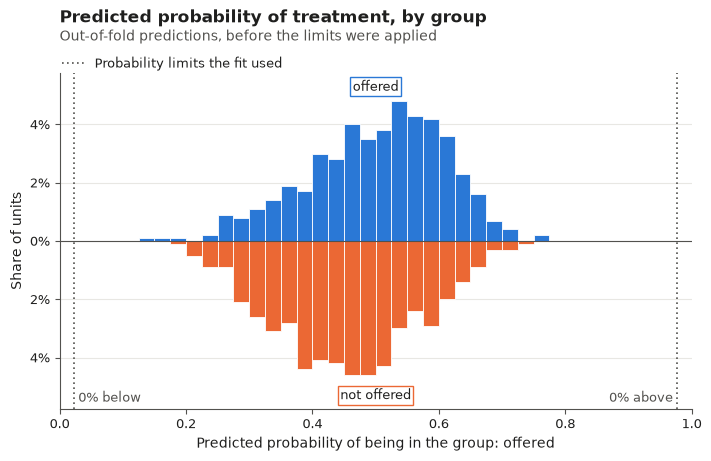

In [11]:
assessment = declared.assess()
support = assessment.report("support")
nuisance = assessment.report("nuisance_models")
scores = assessment.report("score_equations")
(propensity,) = (model for model in nuisance.models if model.name == "propensity")
attention = tuple(item.name for item in assessment.attention)
print("checks that need attention:", attention or "none")
print()
print("overlap, from the fitted treatment model:")
smallest = support.propensity_quantiles["overall"][0.0]
print(f"  smallest predicted offer probability: {smallest:.4f}")
print(f"  share of patients at the weight cap:  {support.truncated['fraction']:.4f}")
for arm, size in support.effective_sample_size.items():
    share = f"{size['effective']:.0f} of {size['n']:.0f} ({size['ratio']:.2f})"
    print(f"  effective sample size, {arm:7s}: {share}")
print()
slope = propensity.metrics["calibration_slope"]
slope_se = propensity.metrics["calibration_slope_se"]
print(f"treatment model calibration slope: {slope:.2f} (standard error {slope_se:.2f})")
print(nuisance.summary().reading)
print(scores.summary().reading)
overlap_fig = plotting.overlap(declared, labels={1.0: "offered", 0.0: "not offered"})

Nothing needs attention: the smallest predicted probability, 0.1488, is far from 0, and the
calibration slope is 1.00. Warning signs would be patients at the cap (the limit the fit puts on
extreme probabilities), or weighted groups that count as far fewer patients than they hold (the
effective sample size); here they count as 92% and 95%. The correction step solved its equations,
which the standard error relies on. In the figure, both groups get probabilities over nearly the same range.
These checks describe the fitted model, which can miss a thin edge of rarely offered patients.

## What if a confounder is missing?

How strong would an unrecorded confounder have to be to erase the effect? The robustness value
answers with one number from 0 to 1: the share of the score's remaining variation, and of the
variation in patients' weights, that a confounder would need to explain on both sides to pull the
estimate to zero.

In [12]:
robustness = declared.sensitivity.robustness_value()
print(f"robustness value:                  {robustness['rv']:.3f}")
print(f"robustness value at the 95% limit: {robustness['rva']:.3f}")

robustness value:                  0.451
robustness value at the 95% limit: 0.417


The robustness value is 0.451 (0.417 for the interval's lower limit): a confounder weaker than that
on both sides cannot erase the effect. The [point-treatment example](point-treatment-tmle.ipynb), on the same simulated program,
finds that a confounder as strong as `discharge_risk` or `medication_burden` would not erase it. Only people who know the program can
judge whether an unrecorded factor could be stronger.

## What we can and can't conclude

For the sponsor: offering navigation to every eligible patient would raise the average 30-day score
by about 0.17 on its 0-to-1 scale (95% interval 0.155 to 0.192); for scale, patients not
offered averaged 0.398. The interval covers sampling
variation only, and it needs both models to be reasonably accurate, which a blend that includes
flexible candidates makes more likely but cannot guarantee. The answer also rests on what no model
choice can check: no unrecorded common cause of the offer and the score, one meaning of an offer,
and no effect of one patient's offer on another's score.

If you screen the treatment model's columns, check which ones it kept, since a dropped confounder
leaves the interval without a guarantee. The page shows one simulated draw with a known answer, which does not show how
the methods perform in general.

## Go deeper

### Try to break the result

These checks change the data in a known way and refit the blended fit. Shuffling the offer among
patients (`placebo`) should give an effect near zero. Adding a column of pure noise
(`random_common_cause`) should barely move the estimate. Refitting on random 70% samples (`subset`)
should give estimates that spread as much as the standard error predicts for that size. Each check
uses 5 refits instead of 20 to stay quick.

In [13]:
from cleverly.validation import refute

checks = refute(
    declared,
    tests=("placebo", "random_common_cause", "subset"),
    n_replicates=5,
)
columns = ["test", "original", "refuted_mean", "refuted_sd", "expectation", "verdict"]
print(checks.to_frame()[columns].round(4).to_string(index=False))

               test  original  refuted_mean  refuted_sd        expectation     verdict
            placebo    0.1736       -0.0037      0.0056                ~ 0 descriptive
random_common_cause    0.1736        0.1741      0.0008           ~ 0.1736 descriptive
             subset    0.1736        0.1747      0.0055 scatter ~ 0.006135 descriptive


With the offer shuffled, the refits average -0.0037, near zero next to 0.1736. With the noise
column they average 0.1741, barely moved, and the 70% refits spread by 0.0055 against the 0.0061
the standard error predicts. Every `verdict` reads `descriptive`: `cleverly` gives a pass or fail
only when a simulation study backs the check for fits like this one, and no study uses these
blended models, so judge the numbers yourself. None of these checks can detect a missing confounder.

### How we know the method works

No simulation study uses this page's blends or its screen, so the evidence is indirect.

| section | simulation study | its data and models |
| --- | --- | --- |
| An ensemble you choose | [stacked point-treatment CV-TMLE](../technical-reference/method-evidence/stacked-point-treatment-cv-tmle.md) | this page's simulated data at 500 patients, with a deliberately overfit regression tree in place of a blend |
| What the default ensemble does | [default learner library at few clusters](../technical-reference/method-evidence/few-cluster-adaptive-learners.md) | the default library for every model, on other simulated data where patients share 10 to 40 teams |
| Try to break the result | [point-treatment refutation rules](../technical-reference/method-evidence/refuter-calibration-point.md) | other data and simpler models, so this page's blended fit gets no verdict |

No study covers the default library on data without teams, or the interval after screening. A
simulation run for this page (`reviews/notebook-review/probes/learner-choice/sweep.py`) repeats its
fits on 200 draws to check its readings; it is not a study that validates the method. The
[nuisance learners](../technical-reference/nuisance-learners.md#what-the-checks-do-not-establish)
entry lists what the library's own checks do and do not establish.

### One model instead of a blend

`meta_learner="discrete"` keeps only the candidate with the smallest cross-validated risk in each
fold, instead of blending (the "discrete" Super Learner).

In [14]:
from sklearn.base import clone

# meta_learner="discrete" keeps only the candidate with the smallest cross-validated risk.
discrete_models = ModelSpec(
    outcome_learner=clone(outcome_ensemble).set_params(meta_learner="discrete"),
    treatment_learner=clone(treatment_ensemble).set_params(meta_learner="discrete"),
)
discrete = effect.estimate(method=replace(declared_method, models=discrete_models))
row = discrete["ate"]
print(f"one candidate per model: ATE {row.psi:.4f}, standard error {row.std_error:.4f}")
print(weight_table(discrete).round(4).to_string(index=False))

one candidate per model: ATE 0.1754, standard error 0.0099
          model candidate  cross-validated risk  weight
treatment model  logistic                0.6845     0.0
treatment model   splines                0.6756     0.8
treatment model  boosting                0.6855     0.2
  outcome model    linear                0.0325     0.0
  outcome model   splines                0.0215     0.0
  outcome model  boosting                0.0198     1.0


Keeping one candidate per model gives 0.1754, close to the blended fit. The weights are averages over the five outer folds, so here they count the folds: the
outcome model picked boosting in all five, and the treatment model picked splines in four (0.8) and
boosting in one (0.2), because all three risks are close, so the best one changes from fold to
fold. A blend uses the information
in all the candidates, which helps when no single one is best everywhere.

## Where to go next

[Flexible models and shared teams](cross-fitting.ipynb) shows why out-of-fold predictions matter
for flexible models. If one recorded characteristic strongly predicts the offer, read [a strong
predictor of treatment](collaborative-tmle.ipynb), which chooses the treatment model's columns by
how they help the estimate. The [methods and learners
guide](../user-guide/methods-learners.md#learner-choices) covers each learner setting, and the
[nuisance learners](../technical-reference/nuisance-learners.md) entry gives the exact rules of the
Super Learner and the default library. The [examples index](index.md) lists every example.